# Missing Data Analysis and Seven-Day OOS Model Experiments

**Data version: v1 (original client dataset)**  
This archived notebook is pinned to the tracked `marvel_data/` snapshot. Its numerical findings must not be presented as v2 results.

This notebook presents the full analytical path from raw data to the selected OOS model. It is the presentation and experimentation notebook; the fixed formal pipeline is implemented separately in `modeling/oos_pipeline.py`.

Rules used throughout:

- A missing Sell-out store-day is unknown, not zero sales, zero inventory, or non-OOS.
- Training EDA ends on February 21, 2026.
- March, April, and May are expanding-window Validation folds with at least a seven-day purge.
- June is the locked final Test period and is not loaded or evaluated.
- Formal labels require all seven future days to be observed.

## 1. Setup and development boundary

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'marvel_data').exists():
    candidates = [ROOT, *ROOT.parents]
    ROOT = next(path for path in candidates if (path / 'marvel_data').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / 'marvel_data'


sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')

# Set True to rerun all model experiments. The complete run takes several minutes.
RUN_MODEL_EXPERIMENTS = False

## Self-contained implementation

The functions below are embedded in this notebook so it can run from a fresh clone without importing project helper modules. They implement the locked pre-June loader, complete calendar, missing-data estimates, seven-day labels, chronological folds, feature families, model training, and metric calculations.

In [2]:
# Embedded from modeling/oos_development.py; this notebook is self-contained.
"""Leakage-controlled development workflow for the seven-day OOS model.

This module intentionally excludes every row dated June 2026 or later. June is
the locked final out-of-time test period and is not available to this workflow.
The command evaluates feature families with expanding training windows and a
seven-day purge before each validation window.
"""


import argparse
import gc
import json
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Iterable

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


LOCKED_TEST_START = pd.Timestamp("2026-06-01")
RANDOM_SEED = 650
MINIMUM_PRECISION = 0.75
MINIMUM_RECALL = 0.70
MINIMUM_AUC = 0.80


@dataclass(frozen=True)
class TimeFold:
    name: str
    train_end: str
    validation_start: str
    validation_end: str

    @property
    def train_end_ts(self) -> pd.Timestamp:
        return pd.Timestamp(self.train_end)

    @property
    def validation_start_ts(self) -> pd.Timestamp:
        return pd.Timestamp(self.validation_start)

    @property
    def validation_end_ts(self) -> pd.Timestamp:
        return pd.Timestamp(self.validation_end)

    def validate(self) -> None:
        purge_days = (self.validation_start_ts - self.train_end_ts).days - 1
        if purge_days < 7:
            raise ValueError(f"{self.name} has only a {purge_days}-day purge gap")
        if self.validation_end_ts + pd.Timedelta(days=7) >= LOCKED_TEST_START:
            raise ValueError(f"{self.name} would require locked June outcomes")


DEFAULT_FOLDS = (
    TimeFold("2026-03", "2026-02-21", "2026-03-01", "2026-03-24"),
    TimeFold("2026-04", "2026-03-23", "2026-04-01", "2026-04-23"),
    TimeFold("2026-05", "2026-04-23", "2026-05-01", "2026-05-24"),
)


BASELINE_NUMERIC = [
    "latest_reported_inventory",
    "latest_reported_oos",
    "days_since_last_report",
    "report_coverage_7d",
    "report_coverage_28d",
    "observed_sales_mean_7d",
    "observed_sales_mean_28d",
    "observed_oos_count_7d",
    "observed_oos_count_28d",
    "estimated_inventory",
    "estimated_inventory_lag_1d",
    "estimated_inventory_lag_7d",
    "estimated_inventory_lag_14d",
    "estimated_inventory_change_1d",
    "estimated_inventory_change_7d",
    "estimated_inventory_change_14d",
    "estimated_inventory_min_7d",
    "estimated_inventory_min_14d",
    "estimated_inventory_min_28d",
    "estimated_sales_mean_7d",
    "estimated_sales_mean_28d",
    "estimated_sales_std_7d",
    "estimated_sales_std_28d",
    "estimated_days_of_supply",
    "expected_sales_next_7d",
    "inventory_cover_vs_next_7d_demand",
    "expected_7d_inventory_shortfall",
    "inventory_below_expected_3d_demand",
    "inventory_below_expected_7d_demand",
    "inventory_was_imputed",
    "sell_in_units_7d",
    "sell_in_units_14d",
    "sell_in_units_28d",
    "sell_in_events_28d",
    "days_since_sell_in",
    "days_since_observed_receipt",
    "observed_receipt_events_28d",
    "weekday_sin",
    "weekday_cos",
    "is_msl",
]

SEASONAL_NUMERIC = [
    "week_of_year_sin",
    "week_of_year_cos",
    "month_sin",
    "month_cos",
    "estimated_sales_lag_7d",
    "estimated_sales_lag_14d",
    "estimated_sales_lag_28d",
    "sales_trend_7d_vs_28d",
    "sales_ratio_7d_vs_28d",
]

REPLENISHMENT_NUMERIC = [
    "learned_invoice_receipt_lag",
    "days_until_invoice_receipt",
    "invoice_receipt_due_3d",
    "invoice_receipt_due_7d",
    "typical_receipt_interval",
    "days_until_typical_receipt",
    "expected_days_until_receipt",
    "typical_receipt_quantity",
    "estimated_depletion_days",
    "receipt_expected_before_depletion",
    "projected_inventory_at_receipt",
    "receipt_quantity_vs_expected_demand",
    "inventory_minus_reorder_trigger",
    "inventory_below_reorder_trigger",
    "historical_pair_oos_rate",
    "historical_store_oos_rate",
    "historical_sku_oos_rate",
]

STATE_DYNAMICS_NUMERIC = [
    "estimated_inventory_lag_2d",
    "estimated_inventory_lag_3d",
    "estimated_inventory_change_2d",
    "estimated_inventory_change_3d",
    "estimated_inventory_min_3d",
    "estimated_inventory_max_7d",
    "estimated_inventory_range_7d",
    "estimated_inventory_slope_3d",
    "estimated_inventory_slope_7d",
    "estimated_sales_mean_3d",
    "estimated_sales_lag_1d",
    "estimated_sales_lag_2d",
    "estimated_sales_lag_3d",
    "days_since_last_observed_oos",
    "observed_oos_count_3d",
    "observed_oos_count_14d",
    "pair_inventory_median",
    "pair_inventory_p25",
    "inventory_vs_pair_median",
    "inventory_vs_pair_p25",
]

HISTORICAL_TARGET_NUMERIC = [
    "pair_future_oos_rate",
    "store_future_oos_rate",
    "sku_future_oos_rate",
    "channel_sku_future_oos_rate",
    "pair_future_oos_examples",
]

CATEGORICAL = ["channel", "segment_tier", "region", "category"]
IDENTITY_CATEGORICAL = CATEGORICAL + ["store_id", "sku_id"]

FEATURE_SETS = {
    "baseline": BASELINE_NUMERIC,
    "baseline_plus_seasonality": BASELINE_NUMERIC + SEASONAL_NUMERIC,
    "baseline_plus_state": BASELINE_NUMERIC + SEASONAL_NUMERIC + STATE_DYNAMICS_NUMERIC,
    "baseline_plus_history": BASELINE_NUMERIC + SEASONAL_NUMERIC + HISTORICAL_TARGET_NUMERIC,
    "baseline_plus_identity": BASELINE_NUMERIC + SEASONAL_NUMERIC,
    "baseline_plus_timing": BASELINE_NUMERIC + REPLENISHMENT_NUMERIC,
    "full": BASELINE_NUMERIC + SEASONAL_NUMERIC + REPLENISHMENT_NUMERIC,
}

DEFAULT_FEATURE_SET_NAMES = (
    "baseline",
    "baseline_plus_seasonality",
    "baseline_plus_timing",
    "full",
)


def add_smoothed_target_history(
    model_frame: pd.DataFrame, *, smoothing: float = 20.0
) -> pd.DataFrame:
    """Add Training-only entity priors without copying a row's own label.

    Validation rows receive a smoothed rate fitted on the complete Training
    portion of the fold. Training rows receive the corresponding leave-one-out
    rate, which prevents the current row's target from becoming its own feature.
    """
    frame = model_frame.copy()
    is_training = frame["split"].eq("Train")
    training = frame.loc[is_training]
    prior = float(training["target"].mean())
    definitions = (
        ("pair_future_oos", ["store_id", "sku_id"]),
        ("store_future_oos", ["store_id"]),
        ("sku_future_oos", ["sku_id"]),
        ("channel_sku_future_oos", ["channel", "sku_id"]),
    )
    original_index = frame.index
    for prefix, keys in definitions:
        stats = (
            training.groupby(keys, observed=True)["target"]
            .agg(["sum", "count"])
            .rename(columns={"sum": f"_{prefix}_sum", "count": f"_{prefix}_count"})
            .reset_index()
        )
        frame = frame.merge(stats, on=keys, how="left", sort=False)
        total = frame[f"_{prefix}_sum"].fillna(0.0)
        count = frame[f"_{prefix}_count"].fillna(0.0)
        rate = (total + smoothing * prior) / (count + smoothing)
        rate.loc[is_training.to_numpy()] = (
            total.loc[is_training.to_numpy()]
            - frame.loc[is_training.to_numpy(), "target"]
            + smoothing * prior
        ) / (count.loc[is_training.to_numpy()] - 1 + smoothing)
        frame[f"{prefix}_rate"] = rate
        if prefix == "pair_future_oos":
            frame["pair_future_oos_examples"] = count
        frame = frame.drop(columns=[f"_{prefix}_sum", f"_{prefix}_count"])
    frame.index = original_index
    return frame


def read_before_locked_test(path: Path, *, chunksize: int = 250_000) -> pd.DataFrame:
    """Load only pre-June rows into the development dataset."""
    parts = []
    for chunk in pd.read_csv(path, parse_dates=["date"], chunksize=chunksize):
        part = chunk.loc[chunk["date"] < LOCKED_TEST_START]
        if not part.empty:
            parts.append(part)
    frame = pd.concat(parts, ignore_index=True)
    if frame["date"].max() >= LOCKED_TEST_START:
        raise AssertionError("Locked-test rows entered the development dataset")
    return frame


def rolling_by_pair(
    frame: pd.DataFrame, column: str, window: int, aggregation: str = "sum"
) -> pd.Series:
    rolling = frame.groupby(
        ["store_id", "sku_id"], sort=False, observed=True
    )[column].rolling(
        window=window, min_periods=1
    )
    return (
        getattr(rolling, aggregation)()
        .reset_index(level=[0, 1], drop=True)
        .sort_index()
    )


def build_base_panel(data_dir: Path) -> pd.DataFrame:
    stores = pd.read_csv(data_dir / "dim_stores.csv")
    products = pd.read_csv(data_dir / "dim_products.csv")
    sell_out = read_before_locked_test(data_dir / "fact_sell_out.csv")
    sell_in = read_before_locked_test(data_dir / "fact_sell_in.csv")
    audits = read_before_locked_test(data_dir / "fact_execution_audits.csv")

    pairs = (
        sell_out[["store_id", "sku_id"]]
        .drop_duplicates()
        .merge(
            stores[["store_id", "channel", "segment_tier", "region"]],
            on="store_id",
            how="left",
            validate="many_to_one",
        )
        .merge(
            products[["sku_id", "category", "is_msl"]],
            on="sku_id",
            how="left",
            validate="many_to_one",
        )
    )
    dates = pd.DataFrame(
        {"date": pd.date_range(sell_out["date"].min(), LOCKED_TEST_START - pd.Timedelta(days=1))}
    )
    pairs["_key"] = 1
    dates["_key"] = 1
    panel = pairs.merge(dates, on="_key").drop(columns="_key")
    panel = (
        panel.merge(
            sell_out,
            on=["date", "store_id", "sku_id"],
            how="left",
            validate="one_to_one",
        )
        .sort_values(["store_id", "sku_id", "date"])
        .reset_index(drop=True)
    )
    panel["is_reported"] = panel["inventory_level"].notna()
    panel["is_out_of_stock"] = panel["is_out_of_stock"].astype("boolean")
    panel["weekday"] = panel["date"].dt.dayofweek.astype("int8")

    pair_group = panel.groupby(["store_id", "sku_id"], sort=False, observed=True)
    future_complete = np.ones(len(panel), dtype=bool)
    future_any_oos = np.zeros(len(panel), dtype=bool)
    for horizon in range(1, 8):
        future_complete &= pair_group["is_reported"].shift(-horizon).eq(True).to_numpy(
            dtype=bool, na_value=False
        )
        future_any_oos |= pair_group["is_out_of_stock"].shift(-horizon).eq(True).to_numpy(
            dtype=bool, na_value=False
        )
    panel["future_7d_complete"] = future_complete
    panel["target"] = np.where(future_complete, future_any_oos.astype("int8"), np.nan)
    panel["target_with_confirmed_positives"] = np.where(
        future_any_oos,
        1,
        np.where(future_complete, 0, np.nan),
    )

    invoices = (
        sell_in.groupby(["store_id", "sku_id", "date"], as_index=False)["units_sold"]
        .sum()
        .rename(columns={"units_sold": "sell_in_units"})
    )
    panel = panel.merge(invoices, on=["store_id", "sku_id", "date"], how="left")
    panel["sell_in_units"] = panel["sell_in_units"].fillna(0).astype("float32")

    # Audit facts are joined on their observed date and carried backward-as-of
    # later in ``add_fold_features``.  Collapsing duplicate same-day audits here
    # keeps the analytical panel at one row per store-SKU-date.
    daily_audits = (
        audits.sort_values(["store_id", "sku_id", "date", "audit_id"])
        .groupby(["store_id", "sku_id", "date"], as_index=False)
        .agg(
            planogram_compliance=("planogram_compliance", "last"),
            shelf_share_pct=("shelf_share_pct", "last"),
            audit_observed=("audit_id", "size"),
        )
    )
    panel = panel.merge(
        daily_audits,
        on=["store_id", "sku_id", "date"],
        how="left",
        validate="one_to_one",
    )
    panel["audit_observed"] = panel["audit_observed"].fillna(0).gt(0)

    for column in ["store_id", "sku_id", "channel", "segment_tier", "region", "category"]:
        panel[column] = panel[column].astype("category")
    if panel["date"].max() >= LOCKED_TEST_START:
        raise AssertionError("Base panel contains locked June dates")
    return panel


def _training_lookup(
    training: pd.DataFrame,
    keys: list[str],
    value: str,
    aggregation: str = "median",
) -> pd.Series:
    return training.groupby(keys, observed=True)[value].agg(aggregation)


def _hierarchical_fill(
    frame: pd.DataFrame,
    specifications: Iterable[tuple[pd.Series, list[str]]],
    fallback: float,
) -> pd.Series:
    result = pd.Series(np.nan, index=frame.index, dtype="float64")
    for lookup, keys in specifications:
        values = frame.join(lookup.rename("_lookup"), on=keys)["_lookup"]
        result = result.fillna(values)
    return result.fillna(fallback)


def add_fold_features(
    base_panel: pd.DataFrame,
    fold: TimeFold,
    training_label_policy: str = "strict_complete",
) -> pd.DataFrame:
    """Create fold-specific features; every learned value uses training only."""
    fold.validate()
    frame = base_panel.loc[base_panel["date"] <= fold.validation_end_ts].copy()
    training_mask = frame["date"] <= fold.train_end_ts
    in_stock_training = frame.loc[
        training_mask & frame["is_reported"] & frame["is_out_of_stock"].ne(True)
    ].copy()

    sales_detailed = _training_lookup(
        in_stock_training, ["store_id", "sku_id", "weekday"], "units_sold_daily"
    )
    sales_pair = _training_lookup(in_stock_training, ["store_id", "sku_id"], "units_sold_daily")
    sales_fallback = _training_lookup(
        in_stock_training, ["channel", "sku_id", "weekday"], "units_sold_daily"
    )
    overall_sales = float(in_stock_training["units_sold_daily"].median())
    frame["imputed_sales_daily"] = _hierarchical_fill(
        frame,
        [
            (sales_detailed, ["store_id", "sku_id", "weekday"]),
            (sales_pair, ["store_id", "sku_id"]),
            (sales_fallback, ["channel", "sku_id", "weekday"]),
        ],
        overall_sales,
    )
    frame["estimated_sales_daily"] = frame["units_sold_daily"].fillna(
        frame["imputed_sales_daily"]
    )

    pair_keys = ["store_id", "sku_id"]
    group = frame.groupby(pair_keys, sort=False, observed=True)
    frame["latest_reported_inventory"] = group["inventory_level"].ffill()
    frame["latest_reported_oos"] = (
        group["is_out_of_stock"].ffill().eq(True).fillna(False).astype("int8")
    )
    date_number = (frame["date"] - frame["date"].min()).dt.days.astype("float32")
    last_report_number = date_number.where(frame["is_reported"]).groupby(
        [frame["store_id"], frame["sku_id"]], observed=True
    ).ffill()
    frame["days_since_last_report"] = date_number - last_report_number

    audit_group = frame.groupby(pair_keys, sort=False, observed=True)
    frame["latest_planogram_compliance"] = (
        audit_group["planogram_compliance"]
        .ffill()
        .astype("boolean")
        .astype("Int8")
    )
    frame["latest_shelf_share_pct"] = audit_group["shelf_share_pct"].ffill()
    last_audit_number = date_number.where(frame["audit_observed"]).groupby(
        [frame["store_id"], frame["sku_id"]], observed=True
    ).ffill()
    frame["days_since_last_audit"] = (date_number - last_audit_number).clip(upper=365)
    frame["has_historical_audit"] = last_audit_number.notna().astype("int8")

    frame["observed_sales_for_sum"] = frame["units_sold_daily"].fillna(0)
    frame["observed_count"] = frame["is_reported"].astype("int8")
    frame["observed_oos_numeric"] = frame["is_out_of_stock"].eq(True).fillna(False).astype("int8")
    for window in (3, 7, 28):
        observed_sum = rolling_by_pair(frame, "observed_sales_for_sum", window)
        observed_count = rolling_by_pair(frame, "observed_count", window)
        frame[f"observed_sales_mean_{window}d"] = observed_sum / observed_count.replace(0, np.nan)
        frame[f"report_coverage_{window}d"] = observed_count / window
        frame[f"estimated_sales_mean_{window}d"] = rolling_by_pair(
            frame, "estimated_sales_daily", window, "mean"
        )
    for window in (3, 7, 14, 28):
        frame[f"observed_oos_count_{window}d"] = rolling_by_pair(
            frame, "observed_oos_numeric", window
        )
    for window in (7, 28):
        frame[f"estimated_sales_std_{window}d"] = rolling_by_pair(
            frame, "estimated_sales_daily", window, "std"
        )

    frame["inventory_segment"] = frame.groupby(
        pair_keys, sort=False, observed=True
    )["is_reported"].cumsum()
    frame["missing_day_sales"] = np.where(
        frame["is_reported"], 0.0, frame["estimated_sales_daily"]
    )
    missing_sales = frame.groupby(pair_keys + ["inventory_segment"], observed=True)[
        "missing_day_sales"
    ].cumsum()
    frame["estimated_inventory"] = (frame["latest_reported_inventory"] - missing_sales).clip(lower=0)
    frame["inventory_was_imputed"] = (~frame["is_reported"]).astype("int8")
    frame["estimated_days_of_supply"] = (
        frame["estimated_inventory"] / frame["estimated_sales_mean_28d"].clip(lower=0.25)
    ).clip(upper=365)

    group = frame.groupby(pair_keys, sort=False, observed=True)
    for lag in (1, 2, 3, 7, 14):
        frame[f"estimated_inventory_lag_{lag}d"] = group["estimated_inventory"].shift(lag)
        frame[f"estimated_inventory_change_{lag}d"] = (
            frame["estimated_inventory"] - frame[f"estimated_inventory_lag_{lag}d"]
        )
    for window in (3, 7, 14, 28):
        frame[f"estimated_inventory_min_{window}d"] = rolling_by_pair(
            frame, "estimated_inventory", window, "min"
        )
    frame["estimated_inventory_max_7d"] = rolling_by_pair(
        frame, "estimated_inventory", 7, "max"
    )
    frame["estimated_inventory_range_7d"] = (
        frame["estimated_inventory_max_7d"] - frame["estimated_inventory_min_7d"]
    )
    frame["estimated_inventory_slope_3d"] = frame["estimated_inventory_change_3d"] / 3
    frame["estimated_inventory_slope_7d"] = frame["estimated_inventory_change_7d"] / 7
    for lag in (1, 2, 3, 7, 14, 28):
        frame[f"estimated_sales_lag_{lag}d"] = group["estimated_sales_daily"].shift(lag)

    last_oos_number = date_number.where(frame["observed_oos_numeric"].eq(1)).groupby(
        [frame["store_id"], frame["sku_id"]], observed=True
    ).ffill()
    frame["days_since_last_observed_oos"] = (date_number - last_oos_number).clip(upper=365)

    frame["sales_trend_7d_vs_28d"] = (
        frame["estimated_sales_mean_7d"] - frame["estimated_sales_mean_28d"]
    )
    frame["sales_ratio_7d_vs_28d"] = (
        frame["estimated_sales_mean_7d"] / frame["estimated_sales_mean_28d"].clip(lower=0.25)
    ).clip(upper=10)
    frame["expected_sales_next_7d"] = 7 * frame["estimated_sales_mean_7d"]
    frame["inventory_cover_vs_next_7d_demand"] = (
        frame["estimated_inventory"] / frame["expected_sales_next_7d"].clip(lower=0.25)
    ).clip(upper=52)
    frame["expected_7d_inventory_shortfall"] = (
        frame["expected_sales_next_7d"] - frame["estimated_inventory"]
    )
    frame["inventory_below_expected_3d_demand"] = (
        frame["estimated_inventory"] <= 3 * frame["estimated_sales_mean_7d"]
    ).astype("int8")
    frame["inventory_below_expected_7d_demand"] = (
        frame["estimated_inventory"] <= frame["expected_sales_next_7d"]
    ).astype("int8")

    frame["sell_in_indicator"] = frame["sell_in_units"].gt(0).astype("int8")
    for window in (7, 14, 28):
        frame[f"sell_in_units_{window}d"] = rolling_by_pair(frame, "sell_in_units", window)
    frame["sell_in_events_28d"] = rolling_by_pair(frame, "sell_in_indicator", 28)
    last_invoice_number = date_number.where(frame["sell_in_indicator"].eq(1)).groupby(
        [frame["store_id"], frame["sku_id"]], observed=True
    ).ffill()
    frame["days_since_sell_in"] = (date_number - last_invoice_number).clip(upper=365)

    group = frame.groupby(pair_keys, sort=False, observed=True)
    frame["previous_date"] = group["date"].shift()
    frame["previous_observed_inventory"] = group["inventory_level"].shift()
    consecutive_observed = (
        frame["is_reported"]
        & frame["previous_observed_inventory"].notna()
        & (frame["date"] - frame["previous_date"]).dt.days.eq(1)
    )
    frame["inferred_receipt"] = np.where(
        consecutive_observed,
        (
            frame["inventory_level"]
            - frame["previous_observed_inventory"]
            + frame["units_sold_daily"]
        ).clip(lower=0),
        np.nan,
    )
    frame["observed_receipt_event"] = frame["inferred_receipt"].fillna(0).gt(0).astype("int8")
    last_receipt_number = date_number.where(frame["observed_receipt_event"].eq(1)).groupby(
        [frame["store_id"], frame["sku_id"]], observed=True
    ).ffill()
    frame["days_since_observed_receipt"] = (date_number - last_receipt_number).clip(upper=365)
    frame["observed_receipt_events_28d"] = rolling_by_pair(
        frame, "observed_receipt_event", 28
    )
    receipt_group = frame.groupby(pair_keys, sort=False, observed=True)
    early_receipt = np.zeros(len(frame), dtype=bool)
    early_receipt_complete = np.ones(len(frame), dtype=bool)
    for horizon in (1, 2):
        early_receipt |= receipt_group["observed_receipt_event"].shift(-horizon).eq(1).to_numpy(
            dtype=bool, na_value=False
        )
        early_receipt_complete &= receipt_group["is_reported"].shift(-horizon).eq(True).to_numpy(
            dtype=bool, na_value=False
        )
    frame["target_early_receipt_next_2d"] = np.where(
        early_receipt_complete, early_receipt.astype("int8"), np.nan
    )

    receipt_training = frame.loc[training_mask & frame["observed_receipt_event"].eq(1)].copy()
    receipt_training["previous_receipt_date"] = receipt_training.groupby(
        pair_keys, observed=True
    )["date"].shift()
    receipt_training["receipt_interval"] = (
        receipt_training["date"] - receipt_training["previous_receipt_date"]
    ).dt.days
    receipt_training["invoice_receipt_lag"] = receipt_training["days_since_sell_in"].where(
        receipt_training["days_since_sell_in"].between(0, 28)
    )

    typical_interval_pair = _training_lookup(
        receipt_training.dropna(subset=["receipt_interval"]), pair_keys, "receipt_interval"
    )
    typical_interval_fallback = _training_lookup(
        receipt_training.dropna(subset=["receipt_interval"]), ["channel", "sku_id"], "receipt_interval"
    )
    interval_overall = float(receipt_training["receipt_interval"].median())
    frame["typical_receipt_interval"] = _hierarchical_fill(
        frame,
        [
            (typical_interval_pair, pair_keys),
            (typical_interval_fallback, ["channel", "sku_id"]),
        ],
        interval_overall,
    )

    lag_events = receipt_training.dropna(subset=["invoice_receipt_lag"])
    lag_pair = _training_lookup(lag_events, pair_keys, "invoice_receipt_lag")
    lag_fallback = _training_lookup(lag_events, ["channel", "sku_id"], "invoice_receipt_lag")
    lag_overall = float(lag_events["invoice_receipt_lag"].median())
    frame["learned_invoice_receipt_lag"] = _hierarchical_fill(
        frame,
        [(lag_pair, pair_keys), (lag_fallback, ["channel", "sku_id"])],
        lag_overall,
    )

    quantity_pair = _training_lookup(receipt_training, pair_keys, "inferred_receipt")
    quantity_fallback = _training_lookup(
        receipt_training, ["channel", "sku_id"], "inferred_receipt"
    )
    quantity_overall = float(receipt_training["inferred_receipt"].median())
    frame["typical_receipt_quantity"] = _hierarchical_fill(
        frame,
        [(quantity_pair, pair_keys), (quantity_fallback, ["channel", "sku_id"])],
        quantity_overall,
    )

    trigger_pair = _training_lookup(receipt_training, pair_keys, "previous_observed_inventory")
    trigger_fallback = _training_lookup(
        receipt_training, ["channel", "sku_id"], "previous_observed_inventory"
    )
    trigger_overall = float(receipt_training["previous_observed_inventory"].median())
    frame["learned_reorder_trigger"] = _hierarchical_fill(
        frame,
        [(trigger_pair, pair_keys), (trigger_fallback, ["channel", "sku_id"])],
        trigger_overall,
    )
    frame["inventory_minus_reorder_trigger"] = (
        frame["estimated_inventory"] - frame["learned_reorder_trigger"]
    )
    frame["inventory_below_reorder_trigger"] = (
        frame["estimated_inventory"] <= frame["learned_reorder_trigger"]
    ).astype("int8")

    frame["days_until_invoice_receipt"] = (
        frame["learned_invoice_receipt_lag"] - frame["days_since_sell_in"]
    )
    frame["days_until_typical_receipt"] = (
        frame["typical_receipt_interval"] - frame["days_since_observed_receipt"]
    )
    invoice_due = frame["days_until_invoice_receipt"].where(frame["days_since_sell_in"].le(28))
    typical_due = frame["days_until_typical_receipt"]
    frame["expected_days_until_receipt"] = pd.concat(
        [invoice_due.clip(lower=0), typical_due.clip(lower=0)], axis=1
    ).min(axis=1)
    frame["invoice_receipt_due_3d"] = invoice_due.between(0, 3).astype("int8")
    frame["invoice_receipt_due_7d"] = invoice_due.between(0, 7).astype("int8")
    frame["estimated_depletion_days"] = (
        frame["estimated_inventory"] / frame["estimated_sales_mean_7d"].clip(lower=0.25)
    ).clip(upper=365)
    frame["receipt_expected_before_depletion"] = (
        frame["expected_days_until_receipt"] < frame["estimated_depletion_days"]
    ).astype("int8")
    frame["projected_inventory_at_receipt"] = (
        frame["estimated_inventory"]
        - frame["estimated_sales_mean_7d"] * frame["expected_days_until_receipt"]
    )
    frame["receipt_quantity_vs_expected_demand"] = (
        frame["typical_receipt_quantity"] / frame["expected_sales_next_7d"].clip(lower=0.25)
    ).clip(upper=52)

    training = frame.loc[training_mask]
    pair_rate = _training_lookup(training, pair_keys, "observed_oos_numeric", "mean")
    store_rate = _training_lookup(training, ["store_id"], "observed_oos_numeric", "mean")
    sku_rate = _training_lookup(training, ["sku_id"], "observed_oos_numeric", "mean")
    overall_oos = float(training["observed_oos_numeric"].mean())
    frame["historical_pair_oos_rate"] = _hierarchical_fill(
        frame, [(pair_rate, pair_keys)], overall_oos
    )

    observed_inventory_training = frame.loc[training_mask & frame["is_reported"]].copy()
    pair_inventory_median = _training_lookup(
        observed_inventory_training, pair_keys, "inventory_level", "median"
    )
    pair_inventory_p25 = observed_inventory_training.groupby(
        pair_keys, observed=True
    )["inventory_level"].quantile(0.25)
    inventory_overall = float(observed_inventory_training["inventory_level"].median())
    inventory_p25_overall = float(observed_inventory_training["inventory_level"].quantile(0.25))
    frame["pair_inventory_median"] = _hierarchical_fill(
        frame, [(pair_inventory_median, pair_keys)], inventory_overall
    )
    frame["pair_inventory_p25"] = _hierarchical_fill(
        frame, [(pair_inventory_p25, pair_keys)], inventory_p25_overall
    )
    frame["inventory_vs_pair_median"] = (
        frame["estimated_inventory"] / frame["pair_inventory_median"].clip(lower=0.25)
    ).clip(upper=52)
    frame["inventory_vs_pair_p25"] = (
        frame["estimated_inventory"] / frame["pair_inventory_p25"].clip(lower=0.25)
    ).clip(upper=52)
    frame["historical_store_oos_rate"] = _hierarchical_fill(
        frame, [(store_rate, ["store_id"])], overall_oos
    )
    frame["historical_sku_oos_rate"] = _hierarchical_fill(
        frame, [(sku_rate, ["sku_id"])], overall_oos
    )

    # Consolidate the many rolling-feature inserts before adding calendar columns.
    frame = frame.copy()
    frame["weekday_sin"] = np.sin(2 * np.pi * frame["weekday"] / 7)
    frame["weekday_cos"] = np.cos(2 * np.pi * frame["weekday"] / 7)
    frame["month_sin"] = np.sin(2 * np.pi * frame["date"].dt.month / 12)
    frame["month_cos"] = np.cos(2 * np.pi * frame["date"].dt.month / 12)
    week = frame["date"].dt.isocalendar().week.astype(float)
    frame["week_of_year_sin"] = np.sin(2 * np.pi * week / 52.18)
    frame["week_of_year_cos"] = np.cos(2 * np.pi * week / 52.18)

    eligible_validation = frame["future_7d_complete"] & frame["latest_reported_inventory"].notna()
    if training_label_policy == "strict_complete":
        eligible_training = eligible_validation
    elif training_label_policy == "confirmed_positive":
        eligible_training = (
            frame["target_with_confirmed_positives"].notna()
            & frame["latest_reported_inventory"].notna()
        )
    else:
        raise ValueError(f"Unknown training label policy: {training_label_policy}")
    train_rows = eligible_training & (frame["date"] <= fold.train_end_ts)
    validation_rows = eligible_validation & frame["date"].between(
        fold.validation_start_ts, fold.validation_end_ts
    )
    model_frame = frame.loc[train_rows | validation_rows].copy()
    model_frame["split"] = np.where(
        model_frame["date"] <= fold.train_end_ts, "Train", "Validation"
    )
    if training_label_policy == "confirmed_positive":
        is_training = model_frame["split"].eq("Train")
        model_frame.loc[is_training, "target"] = model_frame.loc[
            is_training, "target_with_confirmed_positives"
        ]
    model_frame["target"] = model_frame["target"].astype("int8")
    model_frame = add_smoothed_target_history(model_frame)
    if model_frame["date"].max() >= LOCKED_TEST_START:
        raise AssertionError("Fold contains locked June rows")
    return model_frame


def make_pipeline(
    numeric_columns: list[str],
    trees: int,
    categorical_columns: list[str] = CATEGORICAL,
) -> Pipeline:
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True))])
    categorical = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )
    preprocessor = ColumnTransformer(
        [
            ("numeric", numeric, numeric_columns),
            ("categorical", categorical, categorical_columns),
        ],
        verbose_feature_names_out=False,
    )
    model = ExtraTreesClassifier(
        n_estimators=trees,
        max_depth=18,
        min_samples_leaf=12,
        max_features=0.75,
        class_weight="balanced",
        n_jobs=4,
        random_state=RANDOM_SEED,
    )
    return Pipeline([("preprocessor", preprocessor), ("model", model)])


def make_early_receipt_pipeline(trees: int) -> Pipeline:
    numeric_columns = BASELINE_NUMERIC + SEASONAL_NUMERIC + REPLENISHMENT_NUMERIC
    pipeline = make_pipeline(numeric_columns, trees)
    pipeline.set_params(
        model__max_depth=16,
        model__min_samples_leaf=18,
        model__max_features="sqrt",
    )
    return pipeline


def threshold_frontier(y: np.ndarray, probability: np.ndarray) -> pd.DataFrame:
    precision, recall, thresholds = precision_recall_curve(y, probability)
    table = pd.DataFrame(
        {"threshold": thresholds, "precision": precision[:-1], "recall": recall[:-1]}
    )
    table["F1"] = np.where(
        table["precision"] + table["recall"] > 0,
        2 * table["precision"] * table["recall"]
        / (table["precision"] + table["recall"]),
        0,
    )
    return table


def select_threshold(y: np.ndarray, probability: np.ndarray) -> tuple[float, pd.DataFrame]:
    frontier = threshold_frontier(y, probability)
    eligible = frontier.loc[frontier["recall"] >= MINIMUM_RECALL]
    if eligible.empty:
        chosen = frontier.sort_values(["recall", "precision"], ascending=False).iloc[0]
    else:
        chosen = eligible.sort_values(
            ["precision", "F1", "threshold"], ascending=False
        ).iloc[0]
    return float(chosen["threshold"]), frontier


def classification_metrics(
    y: np.ndarray, probability: np.ndarray, threshold: float
) -> dict[str, float | int | bool]:
    predicted = probability >= threshold
    actual = y == 1
    tp = int((predicted & actual).sum())
    fp = int((predicted & ~actual).sum())
    fn = int((~predicted & actual).sum())
    tn = int((~predicted & ~actual).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    auc = roc_auc_score(y, probability)
    result = {
        "threshold": threshold,
        "AUC_ROC": auc,
        "PR_AUC": average_precision_score(y, probability),
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "predicted_positive_rate": float(predicted.mean()),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
    }
    result["meets_all_targets"] = bool(
        precision >= MINIMUM_PRECISION and recall >= MINIMUM_RECALL and auc >= MINIMUM_AUC
    )
    return result


def daily_top_fraction_metrics(predictions: pd.DataFrame, fraction: float = 0.10) -> dict[str, float]:
    selected = []
    for _, day in predictions.groupby("date", sort=False):
        count = max(1, int(np.ceil(len(day) * fraction)))
        selected.append(day.nlargest(count, "probability"))
    chosen = pd.concat(selected, ignore_index=True)
    return {
        "top_fraction": fraction,
        "top_fraction_precision": float(chosen["target"].mean()),
        "top_fraction_recall": float(chosen["target"].sum() / predictions["target"].sum()),
    }


def run_development(
    data_dir: Path,
    folds: tuple[TimeFold, ...] = DEFAULT_FOLDS,
    trees: int = 260,
    feature_set_names: tuple[str, ...] | None = None,
    training_label_policy: str = "strict_complete",
) -> tuple[pd.DataFrame, pd.DataFrame, dict[str, pd.DataFrame]]:
    for fold in folds:
        fold.validate()
    selected_feature_sets = (
        {name: FEATURE_SETS[name] for name in DEFAULT_FEATURE_SET_NAMES}
        if feature_set_names is None
        else {name: FEATURE_SETS[name] for name in feature_set_names}
    )
    base_panel = build_base_panel(data_dir)
    prediction_parts: dict[str, list[pd.DataFrame]] = {
        name: [] for name in selected_feature_sets
    }
    split_rows = []

    for fold in folds:
        model_frame = add_fold_features(base_panel, fold, training_label_policy)
        train = model_frame.loc[model_frame["split"] == "Train"]
        validation = model_frame.loc[model_frame["split"] == "Validation"]
        split_rows.append(
            {
                "fold": fold.name,
                "train_end": fold.train_end,
                "validation_start": fold.validation_start,
                "validation_end": fold.validation_end,
                "train_rows": len(train),
                "validation_rows": len(validation),
                "train_positive_rate": train["target"].mean(),
                "validation_positive_rate": validation["target"].mean(),
            }
        )
        receipt_columns = BASELINE_NUMERIC + SEASONAL_NUMERIC + REPLENISHMENT_NUMERIC + CATEGORICAL
        receipt_pipeline = make_early_receipt_pipeline(trees)
        receipt_train = train.loc[train["target_early_receipt_next_2d"].notna()]
        receipt_pipeline.fit(
            receipt_train[receipt_columns],
            receipt_train["target_early_receipt_next_2d"].astype("int8"),
        )
        early_receipt_probability = receipt_pipeline.predict_proba(validation[receipt_columns])[:, 1]
        del receipt_pipeline
        gc.collect()

        for feature_set, numeric_columns in selected_feature_sets.items():
            categorical_columns = (
                IDENTITY_CATEGORICAL
                if feature_set == "baseline_plus_identity"
                else CATEGORICAL
            )
            pipeline = make_pipeline(numeric_columns, trees, categorical_columns)
            columns = numeric_columns + categorical_columns
            pipeline.fit(train[columns], train["target"])
            probability = pipeline.predict_proba(validation[columns])[:, 1]
            diagnostic_columns = [
                "date",
                "store_id",
                "sku_id",
                "channel",
                "segment_tier",
                "category",
                "is_reported",
                "target",
                "estimated_inventory",
                "estimated_sales_mean_7d",
                "estimated_days_of_supply",
                "expected_sales_next_7d",
                "days_since_sell_in",
                "expected_days_until_receipt",
                "receipt_expected_before_depletion",
                "typical_receipt_quantity",
                "target_early_receipt_next_2d",
            ]
            prediction_parts[feature_set].append(
                validation[diagnostic_columns]
                .assign(
                    fold=fold.name,
                    probability=probability,
                    early_receipt_probability=early_receipt_probability,
                )
                .reset_index(drop=True)
            )
            del pipeline
            gc.collect()
        del model_frame, train, validation
        gc.collect()

    split_summary = pd.DataFrame(split_rows)
    results = []
    frontiers = {}
    combined_predictions = {}
    for feature_set, parts in prediction_parts.items():
        predictions = pd.concat(parts, ignore_index=True)
        y = predictions["target"].to_numpy()
        probability = predictions["probability"].to_numpy()
        threshold, frontier = select_threshold(y, probability)
        frontiers[feature_set] = frontier
        combined_predictions[feature_set] = predictions
        pooled = classification_metrics(y, probability, threshold)
        top = daily_top_fraction_metrics(predictions)
        results.append({"feature_set": feature_set, "fold": "Pooled OOF", **pooled, **top})
        for fold_name, fold_predictions in predictions.groupby("fold", sort=False):
            fold_y = fold_predictions["target"].to_numpy()
            fold_probability = fold_predictions["probability"].to_numpy()
            results.append(
                {
                    "feature_set": feature_set,
                    "fold": fold_name,
                    **classification_metrics(fold_y, fold_probability, threshold),
                    **daily_top_fraction_metrics(fold_predictions),
                }
            )

        clipped_oos = np.clip(probability, 1e-6, 1 - 1e-6)
        base_logit = np.log(clipped_oos / (1 - clipped_oos))
        best_adjusted = None
        for weight in np.linspace(0.0, 3.0, 31):
            adjusted_score = base_logit - weight * predictions["early_receipt_probability"].to_numpy()
            adjusted_threshold, adjusted_frontier = select_threshold(y, adjusted_score)
            adjusted_metrics = classification_metrics(y, adjusted_score, adjusted_threshold)
            candidate = {
                "weight": float(weight),
                "score": adjusted_score,
                "threshold": adjusted_threshold,
                "frontier": adjusted_frontier,
                "metrics": adjusted_metrics,
            }
            if best_adjusted is None or (
                adjusted_metrics["precision"],
                adjusted_metrics["F1"],
                adjusted_metrics["AUC_ROC"],
            ) > (
                best_adjusted["metrics"]["precision"],
                best_adjusted["metrics"]["F1"],
                best_adjusted["metrics"]["AUC_ROC"],
            ):
                best_adjusted = candidate
        adjusted_name = f"{feature_set}_early_receipt_adjusted"
        frontiers[adjusted_name] = best_adjusted["frontier"]
        adjusted_predictions = predictions.assign(probability=best_adjusted["score"])
        combined_predictions[adjusted_name] = adjusted_predictions
        adjusted_top = daily_top_fraction_metrics(adjusted_predictions)
        results.append(
            {
                "feature_set": adjusted_name,
                "fold": "Pooled OOF",
                "adjustment_weight": best_adjusted["weight"],
                **best_adjusted["metrics"],
                **adjusted_top,
            }
        )
        for fold_name, fold_predictions in adjusted_predictions.groupby("fold", sort=False):
            fold_y = fold_predictions["target"].to_numpy()
            fold_score = fold_predictions["probability"].to_numpy()
            results.append(
                {
                    "feature_set": adjusted_name,
                    "fold": fold_name,
                    "adjustment_weight": best_adjusted["weight"],
                    **classification_metrics(
                        fold_y, fold_score, best_adjusted["threshold"]
                    ),
                    **daily_top_fraction_metrics(fold_predictions),
                }
            )
    return pd.DataFrame(results), split_summary, {
        "frontiers": frontiers,
        "predictions": combined_predictions,
    }


def save_results(
    output_dir: Path,
    results: pd.DataFrame,
    split_summary: pd.DataFrame,
    details: dict[str, dict[str, pd.DataFrame]],
    folds: tuple[TimeFold, ...],
    training_label_policy: str,
) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)
    results.to_csv(output_dir / "validation_metrics.csv", index=False)
    split_summary.to_csv(output_dir / "fold_summary.csv", index=False)
    for feature_set, frontier in details["frontiers"].items():
        frontier.to_csv(output_dir / f"{feature_set}_threshold_frontier.csv", index=False)
    for feature_set, predictions in details["predictions"].items():
        predictions.to_csv(output_dir / f"{feature_set}_validation_predictions.csv", index=False)
    metadata = {
        "locked_test_start": str(LOCKED_TEST_START.date()),
        "locked_test_evaluated": False,
        "training_label_policy": training_label_policy,
        "folds": [asdict(fold) for fold in folds],
        "feature_sets": {name: columns for name, columns in FEATURE_SETS.items()},
    }
    (output_dir / "run_metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--data-dir", type=Path, default=Path("marvel_data"))
    parser.add_argument("--output-dir", type=Path, default=Path("outputs/module2_development"))
    parser.add_argument("--trees", type=int, default=260)
    parser.add_argument(
        "--feature-set",
        action="append",
        choices=tuple(FEATURE_SETS),
        help="Run only the named feature set; may be supplied more than once.",
    )
    parser.add_argument(
        "--training-label-policy",
        choices=("strict_complete", "confirmed_positive"),
        default="strict_complete",
        help="Choose whether incomplete-window confirmed positives enter Training.",
    )
    parser.add_argument(
        "--quick",
        action="store_true",
        help="Run only the latest pre-June fold with at most 80 trees.",
    )
    return parser.parse_args()


def main() -> None:
    args = parse_args()
    folds = (DEFAULT_FOLDS[-1],) if args.quick else DEFAULT_FOLDS
    trees = min(args.trees, 80) if args.quick else args.trees
    feature_set_names = tuple(args.feature_set) if args.feature_set else None
    results, split_summary, details = run_development(
        args.data_dir,
        folds,
        trees,
        feature_set_names,
        args.training_label_policy,
    )
    save_results(
        args.output_dir,
        results,
        split_summary,
        details,
        folds,
        args.training_label_policy,
    )
    pooled = results.loc[results["fold"] == "Pooled OOF"].sort_values(
        ["meets_all_targets", "precision", "recall", "AUC_ROC"], ascending=False
    )
    print("DEVELOPMENT FOLDS")
    print(split_summary.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
    print("\nPOOLED OUT-OF-FOLD RESULTS")
    print(pooled.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
    print(f"\nSaved development-only results to {args.output_dir}")
    print("Locked June test evaluated: False")




# Embedded from modeling/missing_analysis.py; this notebook is self-contained.
"""Time-layered missing Sell-out analysis for the OOS development workflow.

Training EDA ends on 2026-02-21.  March, April, and May are reported only as
separate validation stability windows.  June is filtered during CSV reading and
is never summarized by this module.
"""


import argparse
import json
from pathlib import Path

import numpy as np
import pandas as pd



EDA_TRAIN_END = pd.Timestamp("2026-02-21")


def _assign_layer(date: pd.Series) -> pd.Series:
    result = pd.Series("Excluded buffer", index=date.index, dtype="string")
    result.loc[date.le(EDA_TRAIN_END)] = "Training EDA"
    for fold in DEFAULT_FOLDS:
        mask = date.between(fold.validation_start_ts, fold.validation_end_ts)
        result.loc[mask] = f"Validation {fold.name}"
    return result


def build_store_day_panel(data_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    stores = pd.read_csv(data_dir / "dim_stores.csv")
    sell_out = read_before_locked_test(data_dir / "fact_sell_out.csv")
    audits = read_before_locked_test(data_dir / "fact_execution_audits.csv")
    if sell_out["date"].max() >= LOCKED_TEST_START:
        raise AssertionError("Locked June rows entered missing analysis")

    observed = (
        sell_out.groupby(["date", "store_id"], as_index=False)
        .agg(
            observed_sku_rows=("sku_id", "size"),
            store_any_oos=("is_out_of_stock", "max"),
            store_sales_units=("units_sold_daily", "sum"),
            store_average_inventory=("inventory_level", "mean"),
        )
    )
    dates = pd.DataFrame(
        {"date": pd.date_range(sell_out["date"].min(), LOCKED_TEST_START - pd.Timedelta(days=1))}
    )
    base = stores[["store_id", "channel", "segment_tier", "region", "state"]].copy()
    base["_key"] = 1
    dates["_key"] = 1
    panel = (
        base.merge(dates, on="_key")
        .drop(columns="_key")
        .merge(observed, on=["date", "store_id"], how="left", validate="one_to_one")
        .sort_values(["store_id", "date"])
        .reset_index(drop=True)
    )
    panel["is_reported"] = panel["observed_sku_rows"].notna()
    panel["weekday"] = panel["date"].dt.day_name()
    panel["month"] = panel["date"].dt.to_period("M").astype(str)
    panel["analysis_layer"] = _assign_layer(panel["date"])

    audit_store_days = audits[["date", "store_id"]].drop_duplicates().assign(has_audit=True)
    panel = panel.merge(
        audit_store_days, on=["date", "store_id"], how="left", validate="one_to_one"
    )
    panel["has_audit"] = panel["has_audit"].eq(True)
    return panel, sell_out, audits


def _coverage(frame: pd.DataFrame, group_columns: list[str]) -> pd.DataFrame:
    return (
        frame.groupby(group_columns, observed=True, dropna=False)
        .agg(
            possible_store_days=("is_reported", "size"),
            observed_store_days=("is_reported", "sum"),
            coverage=("is_reported", "mean"),
        )
        .reset_index()
    )


def missing_run_table(panel: pd.DataFrame) -> pd.DataFrame:
    frame = panel.copy()
    frame["missing"] = ~frame["is_reported"]
    frame["new_run"] = frame.groupby("store_id", observed=True)["missing"].transform(
        lambda value: value.ne(value.shift())
    )
    frame["run_id"] = frame.groupby("store_id", observed=True)["new_run"].cumsum()
    runs = (
        frame.loc[frame["missing"]]
        .groupby(["store_id", "run_id"], as_index=False, observed=True)
        .agg(
            run_start=("date", "min"),
            run_end=("date", "max"),
            missing_days=("date", "size"),
            channel=("channel", "first"),
            segment_tier=("segment_tier", "first"),
        )
    )
    runs["analysis_layer"] = _assign_layer(runs["run_start"])
    return runs


def missing_after_state(panel: pd.DataFrame) -> pd.DataFrame:
    frame = panel.sort_values(["store_id", "date"]).copy()
    group = frame.groupby("store_id", observed=True)
    frame["prior_day_reported"] = group["is_reported"].shift()
    frame["prior_day_any_oos"] = group["store_any_oos"].shift()
    frame["prior_day_sales"] = group["store_sales_units"].shift()

    training_observed = frame.loc[
        frame["analysis_layer"].eq("Training EDA") & frame["prior_day_reported"].eq(True),
        "prior_day_sales",
    ].dropna()
    low, high = training_observed.quantile([0.25, 0.75])
    frame["prior_sales_band"] = np.select(
        [frame["prior_day_sales"].le(low), frame["prior_day_sales"].ge(high)],
        ["Low (training Q1)", "High (training Q3)"],
        default="Middle",
    )
    frame["next_day_missing"] = ~frame["is_reported"]
    eligible = frame.loc[frame["prior_day_reported"].eq(True)].copy()
    oos = (
        eligible.groupby(["analysis_layer", "prior_day_any_oos"], observed=True)
        .agg(rows=("next_day_missing", "size"), next_day_missing_rate=("next_day_missing", "mean"))
        .reset_index()
        .assign(comparison="Prior-day OOS")
        .rename(columns={"prior_day_any_oos": "group"})
    )
    sales = (
        eligible.groupby(["analysis_layer", "prior_sales_band"], observed=True)
        .agg(rows=("next_day_missing", "size"), next_day_missing_rate=("next_day_missing", "mean"))
        .reset_index()
        .assign(comparison="Prior-day sales band")
        .rename(columns={"prior_sales_band": "group"})
    )
    return pd.concat([oos, sales], ignore_index=True)


def weekday_repeatability(panel: pd.DataFrame) -> pd.DataFrame:
    training = panel.loc[panel["analysis_layer"].eq("Training EDA")]
    profile = _coverage(training, ["store_id", "channel", "weekday"])
    summary = (
        profile.groupby(["store_id", "channel"], observed=True)
        .agg(
            mean_weekday_coverage=("coverage", "mean"),
            min_weekday_coverage=("coverage", "min"),
            max_weekday_coverage=("coverage", "max"),
            weekday_coverage_std=("coverage", "std"),
        )
        .reset_index()
    )
    summary["weekday_coverage_range"] = (
        summary["max_weekday_coverage"] - summary["min_weekday_coverage"]
    )
    return summary


def analyze_missing(data_dir: Path) -> dict[str, pd.DataFrame | dict]:
    panel, sell_out, audits = build_store_day_panel(data_dir)
    included = panel.loc[~panel["analysis_layer"].eq("Excluded buffer")].copy()
    runs = missing_run_table(panel)
    included_runs = runs.loc[~runs["analysis_layer"].eq("Excluded buffer")]

    coverage_by_layer = _coverage(included, ["analysis_layer"])
    coverage_by_month = _coverage(included, ["analysis_layer", "month"])
    coverage_by_weekday = _coverage(included, ["analysis_layer", "weekday"])
    coverage_by_dimension = pd.concat(
        [
            _coverage(included, ["analysis_layer", column])
            .rename(columns={column: "value"})
            .assign(dimension=column)
            for column in ("channel", "segment_tier", "region", "state")
        ],
        ignore_index=True,
    )
    run_summary = (
        included_runs.groupby("analysis_layer", observed=True)
        .agg(
            missing_runs=("missing_days", "size"),
            mean_run_days=("missing_days", "mean"),
            median_run_days=("missing_days", "median"),
            p90_run_days=("missing_days", lambda value: value.quantile(0.90)),
            max_run_days=("missing_days", "max"),
            single_day_share=("missing_days", lambda value: value.eq(1).mean()),
        )
        .reset_index()
    )
    audit_relationship = (
        included.groupby(["analysis_layer", "has_audit"], observed=True)
        .agg(store_days=("is_reported", "size"), sell_out_reporting_rate=("is_reported", "mean"))
        .reset_index()
    )
    metadata = {
        "training_eda_end": str(EDA_TRAIN_END.date()),
        "locked_test_start": str(LOCKED_TEST_START.date()),
        "locked_june_evaluated": False,
        "sell_out_rows_loaded_pre_june": len(sell_out),
        "audit_rows_loaded_pre_june": len(audits),
        "stores": int(panel["store_id"].nunique()),
        "policy": "missing Sell-out store-day is unknown, never zero or non-OOS",
    }
    return {
        "coverage_by_layer": coverage_by_layer,
        "coverage_by_month": coverage_by_month,
        "coverage_by_weekday": coverage_by_weekday,
        "coverage_by_dimension": coverage_by_dimension,
        "missing_run_summary": run_summary,
        "missing_runs": included_runs,
        "missing_after_state": missing_after_state(panel).loc[
            lambda x: ~x["analysis_layer"].eq("Excluded buffer")
        ],
        "audit_relationship": audit_relationship,
        "store_weekday_repeatability": weekday_repeatability(panel),
        "metadata": metadata,
    }


def write_outputs(output_dir: Path, results: dict[str, pd.DataFrame | dict]) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)
    for name, value in results.items():
        if isinstance(value, pd.DataFrame):
            value.to_csv(output_dir / f"{name}.csv", index=False)
        else:
            (output_dir / f"{name}.json").write_text(
                json.dumps(value, indent=2), encoding="utf-8"
            )


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser()
    parser.add_argument("--data-dir", type=Path, default=Path("data/raw"))
    parser.add_argument("--output-dir", type=Path, default=Path("outputs/missing_analysis"))
    return parser.parse_args()


def main() -> None:
    args = parse_args()
    results = analyze_missing(args.data_dir)
    write_outputs(args.output_dir, results)
    print(results["coverage_by_layer"].to_string(index=False))
    print(results["missing_run_summary"].to_string(index=False))




# Embedded from modeling/oos_brief_pipeline.py; this notebook is self-contained.
"""Brief-aligned, leakage-controlled OOS experiment and training pipeline.

The first experiment uses exactly the six conceptual inputs named in the
challenge brief.  Later experiments add one feature family at a time.  June
2026 is never read by this module and remains the locked final test period.
"""


import argparse
import json
from dataclasses import dataclass
from pathlib import Path

import joblib
import pandas as pd
import sklearn


@dataclass(frozen=True)
class FeatureExperiment:
    numeric: tuple[str, ...]
    categorical: tuple[str, ...]
    rationale: str


BRIEF_NUMERIC = (
    "estimated_sales_mean_7d",       # daily sales velocity
    "estimated_inventory",           # current inventory state
    "latest_planogram_compliance",
    "latest_shelf_share_pct",
    "is_msl",
)
BRIEF_CATEGORICAL = ("channel",)

MISSINGNESS_NUMERIC = (
    "days_since_last_report",
    "report_coverage_7d",
    "report_coverage_28d",
    "inventory_was_imputed",
    "has_historical_audit",
    "days_since_last_audit",
)

INVENTORY_DEMAND_NUMERIC = (
    "latest_reported_inventory",
    "latest_reported_oos",
    "observed_sales_mean_7d",
    "observed_sales_mean_28d",
    "observed_oos_count_7d",
    "observed_oos_count_28d",
    "estimated_sales_mean_28d",
    "estimated_sales_std_7d",
    "estimated_inventory_lag_1d",
    "estimated_inventory_lag_7d",
    "estimated_inventory_change_1d",
    "estimated_inventory_change_7d",
    "estimated_inventory_min_7d",
    "estimated_days_of_supply",
    "expected_sales_next_7d",
    "inventory_cover_vs_next_7d_demand",
    "expected_7d_inventory_shortfall",
    "inventory_below_expected_3d_demand",
    "inventory_below_expected_7d_demand",
)

SELL_IN_NUMERIC = (
    "sell_in_units_7d",
    "sell_in_units_14d",
    "sell_in_units_28d",
    "sell_in_events_28d",
    "days_since_sell_in",
)


def _unique(columns: tuple[str, ...]) -> tuple[str, ...]:
    return tuple(dict.fromkeys(columns))

EXPERIMENTS = {
    "brief_baseline": FeatureExperiment(
        BRIEF_NUMERIC,
        BRIEF_CATEGORICAL,
        "Exactly the six conceptual inputs named in the challenge brief.",
    ),
    "brief_plus_missingness": FeatureExperiment(
        BRIEF_NUMERIC + MISSINGNESS_NUMERIC,
        BRIEF_CATEGORICAL,
        "Adds report coverage, freshness, imputation state, and audit freshness.",
    ),
    "brief_plus_inventory_demand": FeatureExperiment(
        BRIEF_NUMERIC + MISSINGNESS_NUMERIC + INVENTORY_DEMAND_NUMERIC,
        BRIEF_CATEGORICAL,
        "Adds past-only inventory trajectory, demand history, and days-of-supply risk.",
    ),
    "brief_plus_sell_in": FeatureExperiment(
        BRIEF_NUMERIC
        + MISSINGNESS_NUMERIC
        + INVENTORY_DEMAND_NUMERIC
        + SELL_IN_NUMERIC,
        BRIEF_CATEGORICAL,
        "Adds lagged invoice volume and recency as weak replenishment signals.",
    ),
    "brief_plus_seasonality": FeatureExperiment(
        BRIEF_NUMERIC
        + MISSINGNESS_NUMERIC
        + INVENTORY_DEMAND_NUMERIC
        + SELL_IN_NUMERIC
        + tuple(SEASONAL_NUMERIC),
        ("channel", "segment_tier", "region", "category"),
        "Adds calendar, demand-trend, and stable store/product segment context.",
    ),
    "operational_engineered": FeatureExperiment(
        _unique(
            tuple(BASELINE_NUMERIC)
            + tuple(SEASONAL_NUMERIC)
            + (
                "latest_planogram_compliance",
                "latest_shelf_share_pct",
                "has_historical_audit",
                "days_since_last_audit",
            )
        ),
        ("channel", "segment_tier", "region", "category"),
        "Consolidates the strongest past-only operational inventory, demand, receipt-history, audit, and calendar features.",
    ),
    "retained_reference": FeatureExperiment(
        _unique(tuple(BASELINE_NUMERIC) + tuple(SEASONAL_NUMERIC)),
        ("channel", "segment_tier", "region", "category"),
        "Reproduces the previously retained operational feature family without the new audit fields.",
    ),
}


def _evaluate_predictions(predictions: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    threshold, frontier = select_threshold(
        predictions["target"].to_numpy(), predictions["probability"].to_numpy()
    )
    rows = []
    pooled = classification_metrics(
        predictions["target"].to_numpy(),
        predictions["probability"].to_numpy(),
        threshold,
    )
    rows.append(
        {
            "fold": "Pooled OOF",
            **pooled,
            **daily_top_fraction_metrics(predictions),
        }
    )
    for fold, frame in predictions.groupby("fold", sort=False):
        rows.append(
            {
                "fold": fold,
                **classification_metrics(
                    frame["target"].to_numpy(),
                    frame["probability"].to_numpy(),
                    threshold,
                ),
                **daily_top_fraction_metrics(frame),
            }
        )
    return pd.DataFrame(rows), frontier


def run_experiments(
    data_dir: Path,
    *,
    folds: tuple[TimeFold, ...] = DEFAULT_FOLDS,
    trees: int = 260,
    experiment_names: tuple[str, ...] | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame, dict[str, pd.DataFrame], dict[str, pd.DataFrame]]:
    panel = build_base_panel(data_dir)
    if panel["date"].max() >= LOCKED_TEST_START:
        raise AssertionError("Locked June rows entered the experiment panel")

    selected_experiments = (
        EXPERIMENTS
        if experiment_names is None
        else {name: EXPERIMENTS[name] for name in experiment_names}
    )
    prediction_parts = {name: [] for name in selected_experiments}
    fold_frames: dict[str, pd.DataFrame] = {}
    fold_rows = []
    for fold in folds:
        frame = add_fold_features(panel, fold, training_label_policy="strict_complete")
        fold_frames[fold.name] = frame
        train = frame.loc[frame["split"].eq("Train")]
        validation = frame.loc[frame["split"].eq("Validation")]
        fold_rows.append(
            {
                "fold": fold.name,
                "train_end": fold.train_end,
                "validation_start": fold.validation_start,
                "validation_end": fold.validation_end,
                "train_rows": len(train),
                "validation_rows": len(validation),
                "train_positive_rate": train["target"].mean(),
                "validation_positive_rate": validation["target"].mean(),
            }
        )
        for name, experiment in selected_experiments.items():
            columns = list(experiment.numeric + experiment.categorical)
            model = make_pipeline(
                list(experiment.numeric), trees, list(experiment.categorical)
            )
            model.fit(train[columns], train["target"])
            part = validation[
                ["date", "store_id", "sku_id", "channel", "is_reported", "target"]
            ].copy()
            part["fold"] = fold.name
            part["probability"] = model.predict_proba(validation[columns])[:, 1]
            prediction_parts[name].append(part)

    metric_parts = []
    predictions = {}
    frontiers = {}
    for name, parts in prediction_parts.items():
        prediction = pd.concat(parts, ignore_index=True)
        metric, frontier = _evaluate_predictions(prediction)
        metric.insert(0, "experiment", name)
        metric_parts.append(metric)
        predictions[name] = prediction
        frontiers[name] = frontier
    return (
        pd.concat(metric_parts, ignore_index=True),
        pd.DataFrame(fold_rows),
        predictions,
        {**frontiers, **{f"fold_frame__{k}": v for k, v in fold_frames.items()}},
    )


def choose_experiment(metrics: pd.DataFrame) -> str:
    pooled = metrics.loc[metrics["fold"].eq("Pooled OOF")].copy()
    pooled = pooled.sort_values(
        ["precision", "PR_AUC", "AUC_ROC"], ascending=False
    )
    return str(pooled.iloc[0]["experiment"])


def fit_final_development_model(
    may_frame: pd.DataFrame,
    experiment_name: str,
    threshold: float,
    *,
    trees: int,
) -> dict:
    """Refit after selection using all eligible pre-June development rows.

    Feature lookups remain frozen at the May fold's Training cutoff, while the
    estimator is refit on both May-fold Training and Validation rows.  This is
    suitable for generating June predictions after the final-test gate is
    explicitly opened; this function itself never reads June.
    """
    experiment = EXPERIMENTS[experiment_name]
    columns = list(experiment.numeric + experiment.categorical)
    training = may_frame.sort_values("date").copy()
    model = make_pipeline(list(experiment.numeric), trees, list(experiment.categorical))
    model.fit(training[columns], training["target"])
    return {
        "pipeline": model,
        "experiment": experiment_name,
        "numeric_features": list(experiment.numeric),
        "categorical_features": list(experiment.categorical),
        "threshold": float(threshold),
        "last_training_prediction_date": str(training["date"].max().date()),
        "training_rows": int(len(training)),
        "locked_test_start": str(LOCKED_TEST_START.date()),
        "scikit_learn_version": sklearn.__version__,
        "target_definition": "any observed OOS from t+1 through t+7; complete windows only",
    }


def write_outputs(
    output_dir: Path,
    metrics: pd.DataFrame,
    folds: pd.DataFrame,
    predictions: dict[str, pd.DataFrame],
    artifacts: dict[str, pd.DataFrame],
    *,
    trees: int,
) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)
    metrics.to_csv(output_dir / "experiment_metrics.csv", index=False)
    folds.to_csv(output_dir / "fold_summary.csv", index=False)
    for name, prediction in predictions.items():
        prediction.to_csv(output_dir / f"{name}_validation_predictions.csv", index=False)
        artifacts[name].to_csv(output_dir / f"{name}_threshold_frontier.csv", index=False)

    selected = choose_experiment(metrics)
    selected_row = metrics.loc[
        metrics["experiment"].eq(selected) & metrics["fold"].eq("Pooled OOF")
    ].iloc[0]
    final_artifact = fit_final_development_model(
        artifacts["fold_frame__2026-05"],
        selected,
        float(selected_row["threshold"]),
        trees=trees,
    )
    joblib.dump(final_artifact, output_dir / "oos_development_model.joblib")
    manifest = {
        "selected_experiment": selected,
        "selection_rule": "highest pooled OOF precision subject to threshold selection at recall >= 0.70",
        "locked_june_evaluated": False,
        "trees": trees,
        "experiments": {
            name: {
                "numeric": list(experiment.numeric),
                "categorical": list(experiment.categorical),
                "rationale": experiment.rationale,
            }
            for name, experiment in EXPERIMENTS.items()
        },
    }
    (output_dir / "run_manifest.json").write_text(
        json.dumps(manifest, indent=2), encoding="utf-8"
    )


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser()
    parser.add_argument("--data-dir", type=Path, default=Path("data/raw"))
    parser.add_argument("--output-dir", type=Path, default=Path("outputs/oos_brief_pipeline"))
    parser.add_argument("--trees", type=int, default=260)
    parser.add_argument("--quick", action="store_true")
    parser.add_argument("--experiment", action="append", choices=tuple(EXPERIMENTS))
    return parser.parse_args()


def main() -> None:
    args = parse_args()
    folds = (DEFAULT_FOLDS[-1],) if args.quick else DEFAULT_FOLDS
    metrics, fold_summary, predictions, artifacts = run_experiments(
        args.data_dir,
        folds=folds,
        trees=args.trees,
        experiment_names=tuple(args.experiment) if args.experiment else None,
    )
    write_outputs(
        args.output_dir,
        metrics,
        fold_summary,
        predictions,
        artifacts,
        trees=args.trees,
    )
    print(metrics.to_string(index=False))




In [3]:
split_design = pd.DataFrame([
    {
        'layer': 'Training EDA',
        'train_end': EDA_TRAIN_END.date(),
        'validation_start': None,
        'validation_end': None,
        'purpose': 'Missing analysis, feature design, and learned fallback rules',
    },
    *[
        {
            'layer': fold.name,
            'train_end': fold.train_end,
            'validation_start': fold.validation_start,
            'validation_end': fold.validation_end,
            'purpose': 'Chronological model validation',
        }
        for fold in DEFAULT_FOLDS
    ],
    {
        'layer': 'Locked Test',
        'train_end': None,
        'validation_start': LOCKED_TEST_START.date(),
        'validation_end': '2026-06-30',
        'purpose': 'One-time final evaluation after model freeze',
    },
])
split_design

,layer,train_end,validation_start,validation_end,purpose
0,Training EDA,2026-02-21,None,None,"Missing analysis, feature design, and learned ..."
1,2026-03,2026-02-21,2026-03-01,2026-03-24,Chronological model validation
2,2026-04,2026-03-23,2026-04-01,2026-04-23,Chronological model validation
3,2026-05,2026-04-23,2026-05-01,2026-05-24,Chronological model validation
4,Locked Test,None,2026-06-01,2026-06-30,One-time final evaluation after model freeze


The Test period is identified for governance only. Every loader used below filters rows at June 1 before returning a DataFrame.

## 2. Load and audit the pre-June source data

In [4]:
stores = pd.read_csv(DATA_DIR / 'dim_stores.csv')
products = pd.read_csv(DATA_DIR / 'dim_products.csv')
sell_out = read_before_locked_test(DATA_DIR / 'fact_sell_out.csv')
sell_in = read_before_locked_test(DATA_DIR / 'fact_sell_in.csv')
audits = read_before_locked_test(DATA_DIR / 'fact_execution_audits.csv')

for frame in (sell_out, sell_in, audits):
    assert frame['date'].max() < LOCKED_TEST_START

source_overview = pd.DataFrame([
    {'table': 'dim_stores', 'rows': len(stores), 'first_date': None, 'last_date': None},
    {'table': 'dim_products', 'rows': len(products), 'first_date': None, 'last_date': None},
    {'table': 'fact_sell_out', 'rows': len(sell_out), 'first_date': sell_out.date.min().date(), 'last_date': sell_out.date.max().date()},
    {'table': 'fact_sell_in', 'rows': len(sell_in), 'first_date': sell_in.date.min().date(), 'last_date': sell_in.date.max().date()},
    {'table': 'fact_execution_audits', 'rows': len(audits), 'first_date': audits.date.min().date(), 'last_date': audits.date.max().date()},
])
source_overview

,table,rows,first_date,last_date
0,dim_stores,221,None,None
1,dim_products,23,None,None
2,fact_sell_out,1565789,2025-01-01,2026-05-31
3,fact_sell_in,260809,2024-12-30,2026-05-25
4,fact_execution_audits,195734,2025-01-01,2026-05-31


In [5]:
quality_checks = pd.Series({
    'duplicate sell-out date-store-SKU keys': sell_out.duplicated(['date', 'store_id', 'sku_id']).sum(),
    'negative daily sales rows': sell_out['units_sold_daily'].lt(0).sum(),
    'negative inventory rows': sell_out['inventory_level'].lt(0).sum(),
    'OOS flag inconsistent with zero inventory': (sell_out['is_out_of_stock'] != sell_out['inventory_level'].eq(0)).sum(),
}, name='rows')
quality_checks.to_frame()

,rows
duplicate sell-out date-store-SKU keys,0
negative daily sales rows,0
negative inventory rows,0
OOS flag inconsistent with zero inventory,0


## 3. Build the complete store-day calendar and identify missing reports

Sell-out missingness occurs mainly as an absent store-day. The analysis therefore starts at store-day grain. A reported day is one where at least one Sell-out row exists for the store; an absent day remains unknown.

In [6]:
store_day_panel, _, _ = build_store_day_panel(DATA_DIR)
store_day_panel[['date', 'store_id', 'channel', 'analysis_layer', 'is_reported', 'observed_sku_rows']].head(10)

,date,store_id,channel,analysis_layer,is_reported,observed_sku_rows
0,2025-01-01,STR-0001,Modern Trade,Training EDA,True,17.0000
1,2025-01-02,STR-0001,Modern Trade,Training EDA,True,17.0000
2,2025-01-03,STR-0001,Modern Trade,Training EDA,True,17.0000
3,2025-01-04,STR-0001,Modern Trade,Training EDA,True,17.0000
4,2025-01-05,STR-0001,Modern Trade,Training EDA,False,NaN
5,2025-01-06,STR-0001,Modern Trade,Training EDA,True,17.0000
6,2025-01-07,STR-0001,Modern Trade,Training EDA,False,NaN
7,2025-01-08,STR-0001,Modern Trade,Training EDA,True,17.0000
8,2025-01-09,STR-0001,Modern Trade,Training EDA,True,17.0000
9,2025-01-10,STR-0001,Modern Trade,Training EDA,False,NaN


In [7]:
missing_results = analyze_missing(DATA_DIR)
coverage = missing_results['coverage_by_layer']
coverage

,analysis_layer,possible_store_days,observed_store_days,coverage
0,Training EDA,92157,64218,0.6968
1,Validation 2026-03,5304,3696,0.6968
2,Validation 2026-04,5083,3542,0.6968
3,Validation 2026-05,5304,3696,0.6968


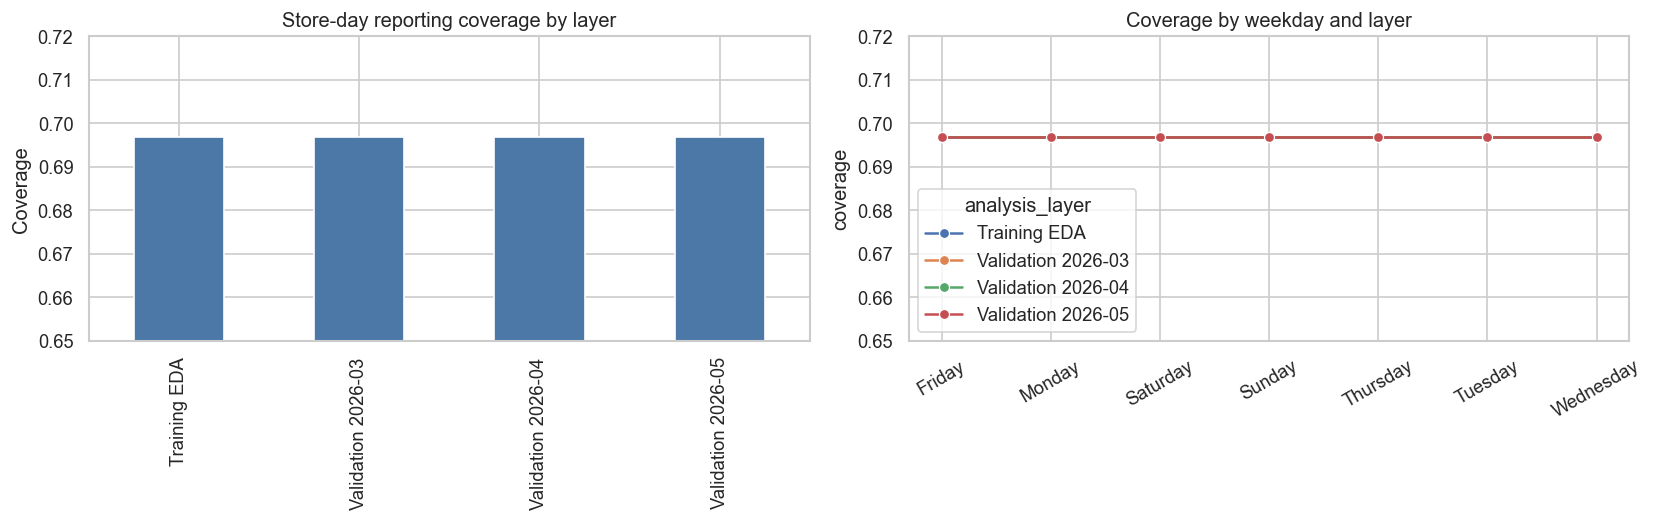

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
coverage.plot.bar(x='analysis_layer', y='coverage', legend=False, color='#4C78A8', ax=axes[0])
axes[0].set_ylim(0.65, 0.72)
axes[0].set_title('Store-day reporting coverage by layer')
axes[0].set_xlabel('')
axes[0].set_ylabel('Coverage')

weekday = missing_results['coverage_by_weekday']
sns.lineplot(data=weekday, x='weekday', y='coverage', hue='analysis_layer', marker='o', ax=axes[1])
axes[1].set_ylim(0.65, 0.72)
axes[1].set_title('Coverage by weekday and layer')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()

Coverage is 69.68% in Training and every Validation fold. No weekday has systematically higher or lower aggregate coverage. This pattern is consistent with a stable synthetic reporting mechanism, but it does not justify treating missing days as zero activity.

## 4. Missingness by business segment and missing-run length

In [9]:
dimension_coverage = missing_results['coverage_by_dimension']
training_dimension_coverage = dimension_coverage.loc[dimension_coverage.analysis_layer.eq('Training EDA')]
display(training_dimension_coverage.loc[training_dimension_coverage.dimension.isin(['channel', 'segment_tier', 'region'])])
missing_results['missing_run_summary']

,analysis_layer,value,possible_store_days,observed_store_days,coverage,dimension
0,Training EDA,Distributor,15012,10425,0.6944,channel
1,Training EDA,Modern Trade,41700,29142,0.6988,channel
2,Training EDA,Traditional Trade,35445,24651,0.6955,channel
12,Training EDA,Tier 1,30024,21018,0.7000,segment_tier
13,Training EDA,Tier 2,35028,24338,0.6948,segment_tier
14,Training EDA,Tier 3,27105,18862,0.6959,segment_tier
24,Training EDA,Midwest,22101,15249,0.6900,region
25,Training EDA,Northeast,23352,16242,0.6955,region
26,Training EDA,Southeast,22518,15863,0.7045,region
27,Training EDA,West,24186,16864,0.6973,region


,analysis_layer,missing_runs,mean_run_days,median_run_days,p90_run_days,max_run_days,single_day_share
0,Training EDA,19484,1.4350,1.0000,2.0000,10,0.6976
1,Validation 2026-03,1138,1.4183,1.0000,2.0000,6,0.6995
2,Validation 2026-04,1070,1.4477,1.0000,2.0000,6,0.6822
3,Validation 2026-05,1147,1.4002,1.0000,2.0000,7,0.7132


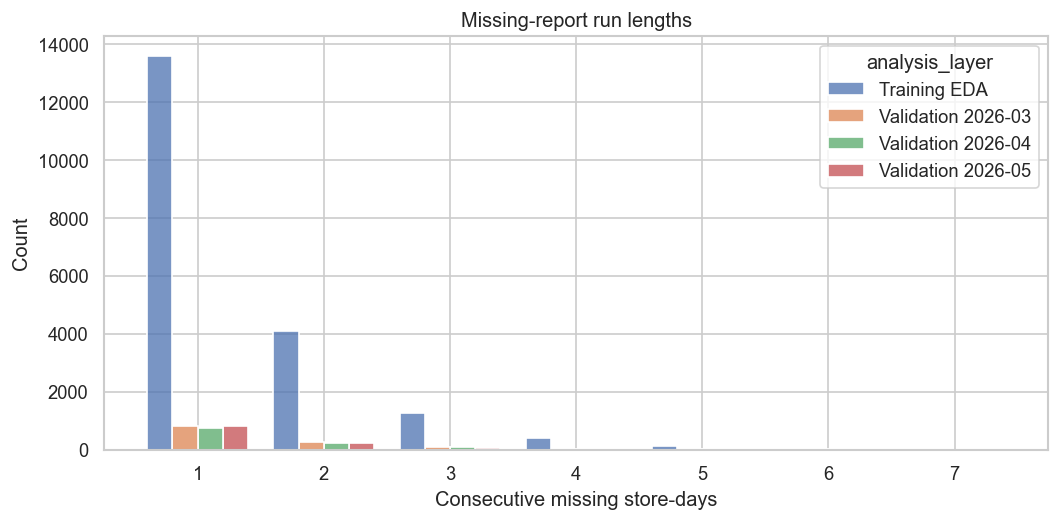

In [10]:
runs = missing_results['missing_runs']
plot_runs = runs.loc[runs.missing_days.le(7)].copy()
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=plot_runs, x='missing_days', hue='analysis_layer', multiple='dodge', discrete=True, shrink=0.8, ax=ax)
ax.set_title('Missing-report run lengths')
ax.set_xlabel('Consecutive missing store-days')
plt.tight_layout()

The median run is one day and the 90th percentile is two days in Training and Validation. Channel, tier, and region differences are small. Short gaps support past-only estimation, but observed and estimated fields must remain separate.

## 5. Is missingness related to OOS, sales, audits, or weekday rotation?

Sales quartile boundaries are fitted on Training only and then applied unchanged to Validation.

In [11]:
missing_after = missing_results['missing_after_state']
audit_relationship = missing_results['audit_relationship']
display(missing_after)
display(audit_relationship)

,analysis_layer,group,rows,next_day_missing_rate,comparison
2,Training EDA,False,20052,0.2999,Prior-day OOS
3,Training EDA,True,44012,0.3046,Prior-day OOS
4,Validation 2026-03,False,973,0.3248,Prior-day OOS
5,Validation 2026-03,True,2723,0.3019,Prior-day OOS
6,Validation 2026-04,False,990,0.3010,Prior-day OOS
7,Validation 2026-04,True,2552,0.3025,Prior-day OOS
8,Validation 2026-05,False,1134,0.3122,Prior-day OOS
9,Validation 2026-05,True,2562,0.3095,Prior-day OOS
13,Training EDA,High (training Q3),16169,0.2983,Prior-day sales band
14,Training EDA,Low (training Q1),16209,0.2995,Prior-day sales band


,analysis_layer,has_audit,store_days,sell_out_reporting_rate
0,Training EDA,False,84409,0.6962
1,Training EDA,True,7748,0.7037
2,Validation 2026-03,False,4857,0.6961
3,Validation 2026-03,True,447,0.7047
4,Validation 2026-04,False,4641,0.6977
5,Validation 2026-04,True,442,0.6878
6,Validation 2026-05,False,4859,0.6958
7,Validation 2026-05,True,445,0.7079


In [12]:
weekday_repeatability = missing_results['store_weekday_repeatability']
weekday_repeatability[['mean_weekday_coverage', 'weekday_coverage_range']].describe(percentiles=[0.25, 0.5, 0.75, 0.9])

,mean_weekday_coverage,weekday_coverage_range
count,221.0000,221.0000
mean,0.6968,0.1622
std,0.0223,0.0470
min,0.6330,0.0715
25%,0.6812,0.1333
50%,0.6975,0.1562
75%,0.7145,0.1898
90%,0.7264,0.2299
max,0.7481,0.3000


Training next-day missingness differs by less than one percentage point after OOS versus non-OOS days and after high versus low sales days. Audit-day reporting coverage is also close to non-audit coverage. Individual stores have some weekday variation, so weekday and freshness may be candidate predictors; there is no evidence for a global weekday zero-fill rule.

## 6. Missing-data treatment used by the model

The model pipeline applies the following past-only logic separately within each Training fold:

1. Build a complete pre-June store-SKU calendar.
2. Keep explicit report, imputation, and freshness flags.
3. Estimate missing sales from in-stock Training medians using `store-SKU-weekday -> store-SKU -> channel-SKU-weekday -> global`.
4. Estimate inventory from the last reported inventory minus cumulative estimated gap sales, bounded at zero.
5. Carry audits backward-as-of only; future audits are never used.
6. Use Sell-in as a lagged invoice signal, never as a confirmed receipt.
7. Create a positive or negative formal label only when all seven future days are observed.

In [13]:
base_panel = build_base_panel(DATA_DIR)
assert base_panel.date.max() < LOCKED_TEST_START
target_summary = pd.DataFrame({
    'rows': [len(base_panel)],
    'reported_rows': [int(base_panel.is_reported.sum())],
    'complete_7d_labels': [int(base_panel.target.notna().sum())],
    'complete_7d_positive_labels': [int(base_panel.target.eq(1).sum())],
})
target_summary

,rows,reported_rows,complete_7d_labels,complete_7d_positive_labels
0,2247180,1565789,176505,29928


## 7. Brief baseline and controlled feature experiments

The baseline uses exactly the six conceptual inputs in the challenge brief: seven-day daily sales velocity, current inventory, latest prior planogram compliance, latest prior shelf share, channel, and MSL status. Later experiments add one feature family at a time.

In [14]:
experiment_design = pd.DataFrame([
    {
        'experiment': name,
        'numeric_features': len(config.numeric),
        'categorical_features': len(config.categorical),
        'rationale': config.rationale,
    }
    for name, config in EXPERIMENTS.items()
])
experiment_design

,experiment,numeric_features,categorical_features,rationale
0,brief_baseline,5,1,Exactly the six conceptual inputs named in the...
1,brief_plus_missingness,11,1,"Adds report coverage, freshness, imputation st..."
2,brief_plus_inventory_demand,30,1,"Adds past-only inventory trajectory, demand hi..."
3,brief_plus_sell_in,35,1,Adds lagged invoice volume and recency as weak...
4,brief_plus_seasonality,44,4,"Adds calendar, demand-trend, and stable store/..."
5,operational_engineered,53,4,Consolidates the strongest past-only operation...
6,retained_reference,49,4,Reproduces the previously retained operational...


In [15]:
brief_features = pd.DataFrame({
    'brief concept': ['daily sales velocity', 'current inventory', 'planogram compliance', 'shelf share', 'channel', 'is_msl'],
    'implemented field': [
        'estimated_sales_mean_7d',
        'estimated_inventory',
        'latest_planogram_compliance',
        'latest_shelf_share_pct',
        'channel',
        'is_msl',
    ],
    'timing rule': [
        'past seven days only',
        'state available at prediction date',
        'latest audit on or before prediction date',
        'latest audit on or before prediction date',
        'static store dimension',
        'static product dimension',
    ],
})
brief_features

,brief concept,implemented field,timing rule
0,daily sales velocity,estimated_sales_mean_7d,past seven days only
1,current inventory,estimated_inventory,state available at prediction date
2,planogram compliance,latest_planogram_compliance,latest audit on or before prediction date
3,shelf share,latest_shelf_share_pct,latest audit on or before prediction date
4,channel,channel,static store dimension
5,is_msl,is_msl,static product dimension


### Run or load the experiment results

Set `RUN_MODEL_EXPERIMENTS = True` in the setup cell to train every candidate directly from the raw data. The default presentation mode loads the saved outputs from the same experiment function so the notebook opens quickly.

In [16]:
result_paths = [
    ROOT / 'outputs' / 'oos_brief_pipeline' / 'experiment_metrics.csv',
    ROOT / 'outputs' / 'oos_operational_challenger' / 'experiment_metrics.csv',
    ROOT / 'outputs' / 'oos_retained_reference' / 'experiment_metrics.csv',
]
cache_available = all(path.exists() for path in result_paths)

if RUN_MODEL_EXPERIMENTS or not cache_available:
    all_metrics, fold_summary, experiment_predictions, experiment_objects = run_experiments(
        DATA_DIR, trees=180
    )
else:
    all_metrics = pd.concat([pd.read_csv(path) for path in result_paths], ignore_index=True)
    fold_summary = pd.read_csv(ROOT / 'outputs' / 'oos_brief_pipeline' / 'fold_summary.csv')

pooled_metrics = all_metrics.loc[all_metrics.fold.eq('Pooled OOF')].copy()
pooled_metrics[['experiment', 'AUC_ROC', 'PR_AUC', 'precision', 'recall', 'F1', 'TP', 'FP', 'FN', 'TN']]

,experiment,AUC_ROC,PR_AUC,precision,recall,F1,TP,FP,FN,TN
0,brief_baseline,0.8793,0.5576,0.4695,0.7000,0.5620,2847,3217,1220,16119
4,brief_plus_missingness,0.8827,0.5659,0.4782,0.7000,0.5682,2847,3107,1220,16229
8,brief_plus_inventory_demand,0.8829,0.5648,0.4708,0.7008,0.5632,2850,3203,1217,16133
12,brief_plus_sell_in,0.8973,0.6577,0.5066,0.7013,0.5882,2852,2778,1215,16558
16,brief_plus_seasonality,0.8963,0.6537,0.5054,0.7000,0.5870,2847,2786,1220,16550
20,operational_engineered,0.8980,0.6579,0.5089,0.7000,0.5894,2847,2747,1220,16589
24,retained_reference,0.8983,0.6578,0.5142,0.7000,0.5929,2847,2690,1220,16646


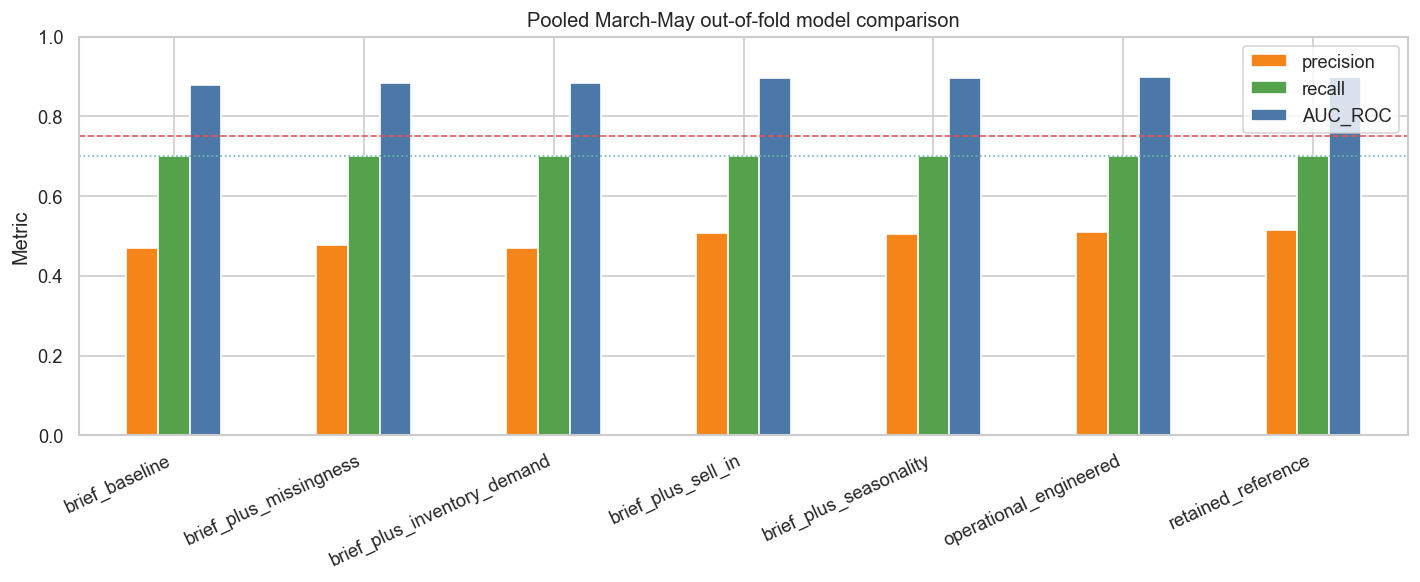

In [17]:
plot_metrics = pooled_metrics.set_index('experiment')[['precision', 'recall', 'AUC_ROC']]
ax = plot_metrics.plot.bar(figsize=(12, 5), color=['#F58518', '#54A24B', '#4C78A8'])
ax.axhline(0.75, color='#E45756', linestyle='--', linewidth=1, label='Precision target')
ax.axhline(0.70, color='#72B7B2', linestyle=':', linewidth=1, label='Recall target')
ax.set_ylim(0, 1)
ax.set_title('Pooled March-May out-of-fold model comparison')
ax.set_ylabel('Metric')
ax.set_xlabel('')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()

The brief baseline reaches Precision 0.469 at Recall 0.700. Missingness fields give a small improvement. The largest gain comes from lagged Sell-in plus broader historical inventory and demand signals. Audit fields and additional seasonality do not improve the required operating point.

## 8. Precision-recall frontier and fold stability

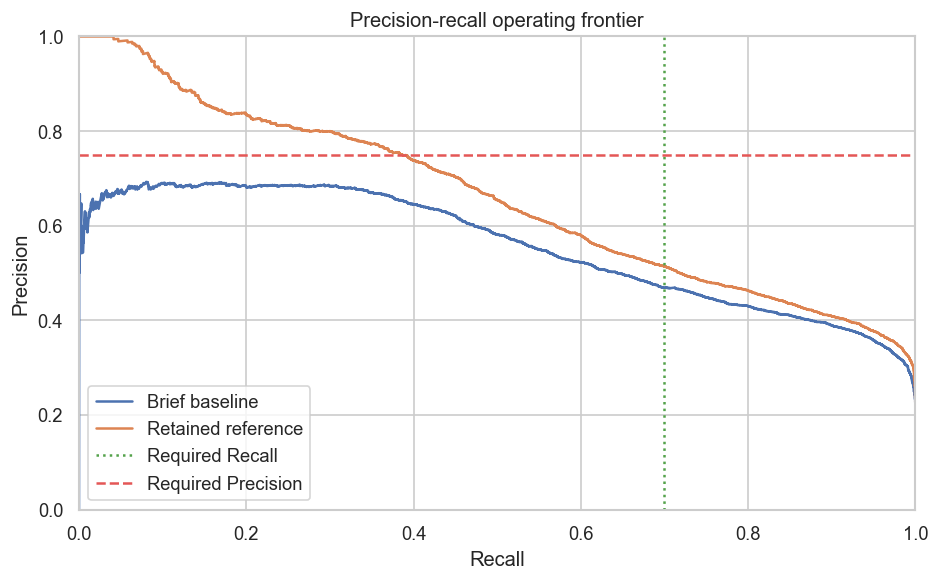

In [18]:
if 'experiment_objects' in globals():
    baseline_frontier = experiment_objects['brief_baseline']
    reference_frontier = experiment_objects['retained_reference']
else:
    baseline_frontier = pd.read_csv(ROOT / 'outputs' / 'oos_brief_pipeline' / 'brief_baseline_threshold_frontier.csv')
    reference_frontier = pd.read_csv(ROOT / 'outputs' / 'oos_retained_reference' / 'retained_reference_threshold_frontier.csv')

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(baseline_frontier.recall, baseline_frontier.precision, label='Brief baseline')
ax.plot(reference_frontier.recall, reference_frontier.precision, label='Retained reference')
ax.axvline(0.70, color='#54A24B', linestyle=':', label='Required Recall')
ax.axhline(0.75, color='#E45756', linestyle='--', label='Required Precision')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-recall operating frontier')
ax.legend()
plt.tight_layout()

In [19]:
reference_by_fold = all_metrics.loc[all_metrics.experiment.eq('retained_reference'), [
    'fold', 'AUC_ROC', 'PR_AUC', 'precision', 'recall', 'TP', 'FP', 'FN', 'TN'
]]
reference_by_fold

,fold,AUC_ROC,PR_AUC,precision,recall,TP,FP,FN,TN
24,Pooled OOF,0.8983,0.6578,0.5142,0.7000,2847,2690,1220,16646
25,2026-03,0.8907,0.6587,0.5180,0.6981,948,882,410,5054
26,2026-04,0.9016,0.6582,0.5129,0.6933,1051,998,465,6392
27,2026-05,0.9028,0.6578,0.5115,0.7108,848,810,345,5200


The retained model is stable across March, April, and May. At pooled Recall 0.700 it produces 2,847 true positives and 2,690 false positives. Precision 0.75 at the same Recall would allow only about 949 false positives, so approximately 65% of the remaining false positives would need to be removed without losing true positives.

## 9. Final model output

This notebook is self-contained. When experiments are run from raw data, the selected `retained_reference` model can be fitted and exported directly in the final cell. The output contains the preprocessing pipeline, classifier, threshold, feature lists, and locked-Test boundary.

Current development result: Precision 0.514, Recall 0.700, ROC-AUC 0.898. The Precision requirement is not met. The available scoring-time data still cannot determine replenishment arrival before depletion accurately enough to eliminate most false positives. June remains locked.

In [20]:
selected_name = 'retained_reference'
selected_metrics = pooled_metrics.loc[pooled_metrics.experiment.eq(selected_name)].iloc[0]

if 'experiment_objects' in globals():
    final_artifact = fit_final_development_model(
        experiment_objects['fold_frame__2026-05'],
        selected_name,
        float(selected_metrics['threshold']),
        trees=180,
    )
    notebook_output_dir = ROOT / 'outputs' / 'oos_notebook'
    notebook_output_dir.mkdir(parents=True, exist_ok=True)
    joblib.dump(final_artifact, notebook_output_dir / 'oos_model.joblib')
    experiment_predictions[selected_name].to_csv(
        notebook_output_dir / 'validation_predictions.csv', index=False
    )
    selected_metrics.to_frame('value').to_csv(notebook_output_dir / 'metrics.csv')
    final_output = pd.DataFrame({
        'artifact': [str(notebook_output_dir / 'oos_model.joblib')],
        'predictions': [str(notebook_output_dir / 'validation_predictions.csv')],
        'locked_june_evaluated': [False],
    })
else:
    final_output = pd.DataFrame({
        'status': ['Presentation mode used embedded/cached experiment results. Set RUN_MODEL_EXPERIMENTS=True to refit and export the model.'],
        'locked_june_evaluated': [False],
    })
final_output

,status,locked_june_evaluated
0,Presentation mode used embedded/cached experim...,False
